# Riesgo de cancelación a 90 días

**Pregunta.** En la fecha de corte del 31 de octubre de 2026, ¿qué clientes tienen mayor riesgo de
cancelar algún servicio en los siguientes 90 días? La unidad de predicción es el cliente y el objetivo
es `churn_90d`. Un score alto sirve para priorizar un seguimiento. Estimar el efecto de una oferta
requeriría un historial de ofertas y resultados individuales.

Se comparan la foto de clientes y la foto enriquecida con tickets previos, usando exactamente la misma
partición. El objetivo sugerido por el reto es **ROC-AUC ≥ 0,75**. Se informa además cuánto riesgo se
captura con una capacidad fija de revisión.

## Reproducción

Desde la raíz de `claro-copilot`, ejecute el notebook en CPU con el entorno fijado del servicio.

```bash
uv run --project services/ml --frozen --python 3.12 \
  --with ipykernel==6.29.5 --with nbclient==0.10.2 --with matplotlib==3.10.0 \
  --with catboost==1.2.8 \
  --with xgboost==3.0.5 --with interpret-core==0.7.4 \
  jupyter-execute --inplace --timeout=600 services/ml/notebooks/comparacion_churn.ipynb
```

Para abrirlo en Jupyter, use un kernel con las mismas dependencias. La carpeta de insumos se busca
al ascender desde el directorio de trabajo. También puede especificarla con `CLARO_INSUMOS_DIR`.
La ejecución conserva las fuentes en modo lectura y muestra únicamente resultados agregados.

In [1]:
import hashlib
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay, average_precision_score, brier_score_loss, roc_auc_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

seed = 42
cwd = Path.cwd()
ancestors = (cwd, *cwd.parents)
root = next((p for p in ancestors if (p / "services/ml/pyproject.toml").is_file()), None)
if root is None:
    raise FileNotFoundError("Ejecute el notebook desde el repositorio claro-copilot.")

override = os.getenv("CLARO_INSUMOS_DIR")
insumos = Path(override).expanduser() if override else next(
    (p / "Insumos_Prueba_Consultor_IA" for p in ancestors
     if (p / "Insumos_Prueba_Consultor_IA").is_dir()),
    root.parent / "Insumos_Prueba_Consultor_IA",
)
if not (insumos / "03_datos").is_dir():
    raise FileNotFoundError("Configure CLARO_INSUMOS_DIR con la ruta a los insumos.")

pd.options.display.max_columns = 18
plt.rcParams.update({"figure.dpi": 125, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {sys.version.split()[0]} · scikit-learn {sklearn.__version__} · pandas {pd.__version__}")

def read_csv(name):
    path = insumos / "03_datos" / name
    print(f"{name} · SHA-256 {hashlib.sha256(path.read_bytes()).hexdigest()}")
    return pd.read_csv(path)

Python 3.12.14 · scikit-learn 1.6.1 · pandas 2.2.3


## Auditoría y disponibilidad de datos

Se conservan los clientes de la foto, incluidos los que carecen de tickets. La ventana de historial
termina a medianoche del **1 de noviembre**, de modo que incluye el día completo de la foto. Contamos
los tickets por fecha de apertura y medimos días desde el más reciente. Usamos la categoría
registrada cuando el cierre estimado es anterior al corte. Los tickets sin ese cierre quedan
en un conteo propio. Auditamos la concordancia con los conteos de 90 días de la foto original.

Las antigüedades negativas pasan a dato faltante. Conservamos los valores de facturación en cero
y usamos logaritmo para el consumo, con auditoría de valores extremos. Identificamos explícitamente
planes inaplicables y preservamos los faltantes numéricos para la imputación. Los datos de satisfacción,
escalamiento y tiempo de resolución del ticket quedan fuera de los predictores. Usamos la
duración solo para estimar si estaba disponible la categoría al corte.

In [2]:
from datetime import date, timedelta

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split

raw_clients = read_csv("clientes_churn.csv")
raw_tickets = read_csv("tickets.csv")
clients = raw_clients.drop_duplicates().reset_index(drop=True)
tickets = raw_tickets.drop_duplicates().reset_index(drop=True)
required = {
    "cliente_id", "fecha_corte", "ciudad", "tipo_servicio", "plan_hogar", "plan_movil",
    "valor_mensual", "antiguedad_meses", "dias_mora", "tickets_90d", "tickets_tecnicos_90d",
    "caidas_servicio_90d", "uso_datos_gb_mes", "metodo_pago", "nps_ultimo",
    "ofertas_retencion_12m", "churn_90d",
}
assert required <= set(clients) and clients["cliente_id"].notna().all()
assert clients["cliente_id"].is_unique and tickets["ticket_id"].is_unique
assert clients["fecha_corte"].notna().all() and clients["fecha_corte"].nunique() == 1
assert set(clients["churn_90d"]) == {0, 1} and clients["churn_90d"].notna().all()

photo_date = date.fromisoformat(clients["fecha_corte"].iloc[0])
end_date = photo_date + timedelta(days=1)
cutoff = pd.Timestamp(end_date)
tickets["fecha_creacion"] = pd.to_datetime(tickets["fecha_creacion"], errors="raise")
assert tickets["fecha_creacion"].notna().all()
tickets["categoria"] = tickets["categoria"].str.strip().str.lower()
y = clients["churn_90d"].astype(int)

num = [
    "valor_mensual", "antiguedad_meses", "dias_mora", "tickets_90d", "tickets_tecnicos_90d",
    "caidas_servicio_90d", "consumo_log", "nps_ultimo", "ofertas_retencion_12m",
]
cat = ["ciudad", "tipo_servicio", "plan_hogar", "plan_movil", "metodo_pago"]

audit = pd.Series({
    "Filas de clientes entregadas": len(raw_clients),
    "Duplicados exactos de cliente": len(raw_clients) - len(clients),
    "Clientes únicos": len(clients),
    "Bajas a 90 días": int(y.sum()),
    "Antigüedades negativas": int(clients["antiguedad_meses"].lt(0).sum()),
    "Cargos mensuales en cero": int(clients["valor_mensual"].eq(0).sum()),
    "Consumo superior a 1.000 GB": int(clients["uso_datos_gb_mes"].gt(1000).sum()),
    "Tickets sin correspondencia en la foto": int((~tickets["cliente_id"].isin(clients["cliente_id"])).sum()),
    "Fecha de la foto": photo_date.isoformat(),
}, name="Resultado")
display(audit.to_frame())
display(clients.isna().sum().loc[lambda counts: counts.gt(0)].to_frame("Faltantes originales"))

raw_features = clients.assign(consumo_log=np.log1p(clients["uso_datos_gb_mes"].where(
    clients["uso_datos_gb_mes"].ge(0)
)))
snapshot = raw_features[cat + num].copy()
snapshot["antiguedad_meses"] = snapshot["antiguedad_meses"].where(snapshot["antiguedad_meses"].ge(0))
has_home = clients["tipo_servicio"].isin(["hogar", "convergente"])
has_mobile = clients["tipo_servicio"].isin(["movil", "convergente"])
snapshot.loc[~has_home, "plan_hogar"] = "__no_aplica__"
snapshot.loc[~has_mobile, "plan_movil"] = "__no_aplica__"
snapshot.loc[~has_home, "caidas_servicio_90d"] = np.nan
snapshot.loc[~has_mobile, "consumo_log"] = np.nan
snapshot[cat] = snapshot[cat].fillna("__sin_dato__").astype(str)

expected_categories = ["cancelacion", "consulta_planes", "facturacion", "portabilidad", "soporte_tecnico"]
assert tickets["categoria"].isin(expected_categories).all()
duration = pd.to_numeric(tickets["tiempo_resolucion_horas"], errors="coerce")
estimated_close = tickets["fecha_creacion"] + pd.to_timedelta(duration.where(duration.ge(0) & duration.lt(9999)), unit="h")
category_available = estimated_close.lt(cutoff)
unknown_category = "categoria_no_disponible"
tickets["categoria_al_corte"] = tickets["categoria"].where(category_available, unknown_category)
history_categories = [*expected_categories, unknown_category]
history = pd.DataFrame(index=clients.index)
for days in (30, 90):
    recent = tickets.loc[
        tickets["fecha_creacion"].ge(pd.Timestamp(end_date - timedelta(days=days)))
        & tickets["fecha_creacion"].lt(cutoff)
    ]
    assert recent["fecha_creacion"].lt(cutoff).all()
    counts = pd.crosstab(recent["cliente_id"], recent["categoria_al_corte"]).reindex(
        columns=history_categories, fill_value=0
    )
    for category in history_categories:
        history[f"{category}_ultimos_{days}d"] = clients["cliente_id"].map(counts[category]).fillna(0).astype(int)

last = tickets.loc[tickets["fecha_creacion"].lt(cutoff)].groupby("cliente_id")["fecha_creacion"].max()
history["dias_desde_ultimo_ticket"] = (cutoff - clients["cliente_id"].map(last)).dt.total_seconds() / 86400
assert history["dias_desde_ultimo_ticket"].dropna().gt(0).all()
computed_90d = history[[f"{category}_ultimos_90d" for category in history_categories]].sum(axis=1)
matched = computed_90d.eq(clients["tickets_90d"])
print(f"Concordancia de tickets a 90 días entre fuentes  {matched.sum()}/{len(clients)}")
print(f"Clientes con algún ticket previo  {history['dias_desde_ultimo_ticket'].notna().sum()}")
print(f"Tickets de 90 días sin categoría disponible  {history[f'{unknown_category}_ultimos_90d'].sum()}")

feature_sets = {"Foto": snapshot, "Foto + historial": pd.concat([snapshot, history], axis=1)}
assert all(X.index.equals(y.index) and not {"churn_90d", "cliente_id", "fecha_corte"} & set(X)
           for X in feature_sets.values())

clientes_churn.csv · SHA-256 5e2ebd9467daacb5f87196341bd13e4dd5bac877ab5a906f76d41f009b35ab08
tickets.csv · SHA-256 c922f1984c060433d74daf561289e88a1d82151c403461614ec5e991a2a27d96


,Resultado
Filas de clientes entregadas,3012
Duplicados exactos de cliente,12
Clientes únicos,3000
Bajas a 90 días,451
Antigüedades negativas,15
Cargos mensuales en cero,9
Consumo superior a 1.000 GB,6
Tickets sin correspondencia en la foto,0
Fecha de la foto,2026-10-31


,Faltantes originales
ciudad,40
plan_hogar,1048
plan_movil,1198
uso_datos_gb_mes,1198
nps_ultimo,862


Concordancia de tickets a 90 días entre fuentes  3000/3000
Clientes con algún ticket previo  1544
Tickets de 90 días sin categoría disponible  8


## Modelos, ajuste y conjunto reservado

| Modelo | Qué se compara |
| --- | --- |
| Prevalencia | Probabilidad constante igual a la frecuencia observada en entrenamiento |
| Regresión logística L2 | Señales aditivas y regularización, con escalado de las variables numéricas |
| Random Forest | Interacciones mediante árboles ajustados en muestras distintas |
| HistGradientBoosting | Árboles secuenciales con regularización mediante hojas mínimas y máximas |
| CatBoost | Boosting con tratamiento nativo de categorías |

Las imputaciones, vocabulario de categorías y escalas se estiman dentro de cada fold.
Se reserva un 20 % estratificado de clientes. En el 80 % de desarrollo se usa una rejilla pequeña
y los mismos cinco folds para los modelos y las dos variantes de datos. El ganador se fija por
ROC-AUC promedio, seguido de AP y Brier. AP resume la curva precisión-recall y Brier mide el error
cuadrático de las probabilidades. En Brier, los valores menores indican menor error.

[HistGradientBoosting](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html) ·
[Random Forest](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.RandomForestClassifier.html) ·
[CatBoost](https://proceedings.neurips.cc/paper/2018/hash/14491b756b3a51daac41c24863285549-Abstract.html) ·
[Average Precision](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.average_precision_score.html)

In [3]:
def tabular_models(cat, num):
    def encoder(dense=False, scale=False):
        numeric = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
        if scale:
            numeric = make_pipeline(numeric, StandardScaler())
        return ColumnTransformer([
            ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=not dense), cat),
            ("numericas", numeric, num),
        ], sparse_threshold=0 if dense else 0.3)

    return {
        "Prevalencia": (DummyClassifier(strategy="prior"), {}),
        "Regresión logística L2": (
            make_pipeline(encoder(scale=True), LogisticRegression(solver="liblinear", max_iter=1000,
                                                                 random_state=seed)),
            {"logisticregression__C": [0.1, 1.0, 10.0]},
        ),
        "Random Forest": (
            make_pipeline(encoder(), RandomForestClassifier(n_estimators=240, n_jobs=2, random_state=seed)),
            {"randomforestclassifier__max_depth": [4, 8],
             "randomforestclassifier__min_samples_leaf": [8, 20]},
        ),
        "HistGradientBoosting": (
            make_pipeline(encoder(dense=True), HistGradientBoostingClassifier(
                max_iter=150, learning_rate=0.05, early_stopping=False, random_state=seed
            )),
            {"histgradientboostingclassifier__max_leaf_nodes": [7, 15],
             "histgradientboostingclassifier__min_samples_leaf": [20, 40]},
        ),
    }

def metrics(actual, score):
    return {
        "ROC-AUC": roc_auc_score(actual, score),
        "AP": average_precision_score(actual, score),
        "Brier": brier_score_loss(actual, score),
    }

def fits_and_scores(model, params, X, y, train, test):
    fitted = clone(model).set_params(**params).fit(X.iloc[train], y.iloc[train])
    return fitted.predict_proba(X.iloc[test])[:, 1]

def choose_models(feature_sets, model_sets, y, splits, ranking):
    rows = []
    for scenario, X in feature_sets.items():
        for name, (model, grid) in model_sets[scenario].items():
            for params in ParameterGrid(grid):
                oof = np.full(len(y), np.nan)
                results = []
                for train, validation in splits:
                    scores = fits_and_scores(model, params, X, y, train, validation)
                    assert np.isnan(oof[validation]).all()
                    oof[validation] = scores
                    results.append(metrics(y.iloc[validation], scores))
                fold_scores = pd.DataFrame(results)
                rows.append({
                    "Escenario": scenario, "Modelo": name, "Parámetros": params,
                    **fold_scores.mean().to_dict(), **(fold_scores.std(ddof=0).add_suffix(" DE").to_dict()),
                    "folds": results, "oof": oof,
                })
    trials = pd.DataFrame(rows).sort_values(ranking, ascending=[False, False, True], kind="stable")
    return trials.drop_duplicates(["Escenario", "Modelo"]).reset_index(drop=True)

def test_models(picks, feature_sets, model_sets, y, train, test):
    scores = {}
    for _, row in picks.iterrows():
        scenario, name = row["Escenario"], row["Modelo"]
        model, _ = model_sets[scenario][name]
        scores[scenario, name] = fits_and_scores(
            model, row["Parámetros"], feature_sets[scenario], y, train, test,
        )
    return scores

def at_capacity(actual, scores, fraction):
    y = np.asarray(actual, dtype=int)
    # La misma semilla rompe empates para todas las curvas y modelos.
    tie_break = np.random.default_rng(seed).permutation(len(y))
    order = np.lexsort((tie_break, -np.asarray(scores)))
    k = int(np.ceil(fraction * len(y)))
    tp = int(y[order[:k]].sum())
    precision = tp / k
    return {
        "Revisados": k, "Positivos capturados": tp, "Falsos positivos": k - tp,
        "Precisión": precision, "Recall": tp / y.sum(), "Lift": precision / y.mean(),
    }

def comparison_plots(actual, scores, title):
    fig, (ax_pr, ax_cal) = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
    for label, values in scores.items():
        if np.ptp(values) > 0:
            PrecisionRecallDisplay.from_predictions(actual, values, name=label, ax=ax_pr)
        CalibrationDisplay.from_predictions(actual, values, n_bins=5, strategy="quantile",
                                            name=label, ax=ax_cal)
    ax_pr.axhline(np.mean(actual), linewidth=1, linestyle="--", color="#666666", label="Tasa base")
    ax_pr.legend(loc="upper right", fontsize=8)
    handles, labels = ax_cal.get_legend_handles_labels()
    labels = ["Calibración ideal" if value == "Perfectly calibrated" else value for value in labels]
    ax_cal.legend(handles, labels, loc="lower right", fontsize=8)
    ax_pr.set(title="Precisión y recall", xlabel="Recall", ylabel="Precisión")
    ax_cal.set(title="Calibración", xlabel="Probabilidad media predicha",
               ylabel="Proporción de casos positivos")
    fig.suptitle(title, x=0.02, ha="left")
    plt.show()

def decimal(value):
    return f"{value:.3f}".replace(".", ",")

In [4]:
model_sets = {}
for scenario, X in feature_sets.items():
    model_sets[scenario] = tabular_models(cat, [column for column in X if column not in cat])
    model_sets[scenario]["CatBoost"] = (
        CatBoostClassifier(
            iterations=300, learning_rate=0.03, l2_leaf_reg=5, cat_features=cat,
            random_seed=seed, thread_count=2, verbose=False, allow_writing_files=False,
        ),
        {"depth": [4, 6]},
    )

dev, test = train_test_split(np.arange(len(clients)), test_size=0.2, random_state=seed, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
splits = [(dev[tr], dev[val]) for tr, val in cv.split(dev, y.iloc[dev])]
assert not set(dev) & set(test) and len(dev) + len(test) == len(clients)
assert np.array_equal(np.sort(np.concatenate([val for _, val in splits])), np.sort(dev))
assert all(
    not set(tr) & set(val) and not set(np.r_[tr, val]) & set(test) and set(y.iloc[val]) == {0, 1}
    for tr, val in splits
)
print(f"Desarrollo  {len(dev)} clientes, {y.iloc[dev].sum()} bajas · "
      f"Prueba  {len(test)} clientes, {y.iloc[test].sum()} bajas")

ranking = ["ROC-AUC", "AP", "Brier"]
with threadpool_limits(limits=2):
    picks = choose_models(feature_sets, model_sets, y, splits, ranking)
    winner = tuple(picks.loc[0, ["Escenario", "Modelo"]])
    heldout = test_models(picks, feature_sets, model_sets, y, dev, test)
display(picks[["Escenario", "Modelo", *ranking, "ROC-AUC DE", "Parámetros"]].round(3))
print(f"Ganador fijado en desarrollo  {' · '.join(winner)}")

Desarrollo  2400 clientes, 361 bajas · Prueba  600 clientes, 90 bajas


,Escenario,Modelo,ROC-AUC,AP,Brier,ROC-AUC DE,Parámetros
0,Foto + historial,CatBoost,0.713,0.353,0.117,0.017,{'depth': 4}
1,Foto,CatBoost,0.711,0.337,0.118,0.018,{'depth': 4}
2,Foto,Random Forest,0.701,0.331,0.118,0.018,"{'randomforestclassifier__max_depth': 8, 'rand..."
3,Foto + historial,Random Forest,0.700,0.334,0.120,0.021,"{'randomforestclassifier__max_depth': 4, 'rand..."
4,Foto,Regresión logística L2,0.699,0.340,0.117,0.016,{'logisticregression__C': 0.1}
5,Foto + historial,Regresión logística L2,0.693,0.330,0.118,0.017,{'logisticregression__C': 0.1}
6,Foto,HistGradientBoosting,0.693,0.322,0.119,0.031,{'histgradientboostingclassifier__max_leaf_nod...
7,Foto + historial,HistGradientBoosting,0.691,0.330,0.119,0.033,{'histgradientboostingclassifier__max_leaf_nod...
8,Foto,Prevalencia,0.500,0.150,0.128,0.000,{}
9,Foto + historial,Prevalencia,0.500,0.150,0.128,0.000,{}


Ganador fijado en desarrollo  Foto + historial · CatBoost


## Rendimiento en la prueba reservada

La tabla mantiene el orden elegido en desarrollo. Las bandas del 10 % y 20 % representan capacidades
de contacto hipotéticas. Se calcula el ranking sin usar la etiqueta y se aplica el mismo desempate
determinista a todos los modelos. El lift divide la precisión del grupo seleccionado entre la tasa
base de cancelación. La selección de casos en el baseline constante se resuelve por ese desempate.

Los intervalos del 95 % se calculan con 1.000 remuestras estratificadas de clientes del conjunto de
prueba. Describen incertidumbre de muestreo dentro de la foto de octubre.

ROC-AUC     AP  Brier
Escenario        Modelo                                       
Foto + historial CatBoost                  0.698  0.310  0.118
Foto             CatBoost                  0.689  0.322  0.117
                 Random Forest             0.682  0.322  0.118
Foto + historial Random Forest             0.701  0.321  0.119
Foto             Regresión logística L2    0.714  0.380  0.113
Foto + historial Regresión logística L2    0.716  0.381  0.113
Foto             HistGradientBoosting      0.677  0.339  0.117
Foto + historial HistGradientBoosting      0.678  0.346  0.117
Foto             Prevalencia               0.500  0.150  0.128
Foto + historial Prevalencia               0.500  0.150  0.128

Revisados  \
Escenario        Modelo                 Capacidad              
Foto + historial CatBoost               10%               60   
                                        20%              120   
Foto             CatBoost               10%               60   
                                        20%              120   
                 Random Forest          10%               60   
                                        20%              120   
Foto + historial Random Forest          10%               60   
                                        20%              120   
Foto             Regresión logística L2 10%               60   
                                        20%              120   
Foto + historial Regresión logística L2 10%               60   
                                        20%              120   
Foto             HistGradientBoosting   10%               60   
                                        20%              120   
Foto + historial HistGradientBoosting   10%               60   
                                        20%              120   
Foto             Prevalencia            10%               60   
                                        20%              120   
Foto + historial Prevalencia            10%               60   
                                        20%              120   

                                                   Positivos capturados  \
Escenario        Modelo                 Capacidad                         
Foto + historial CatBoost               10%                          24   
                                        20%                          34   
Foto             CatBoost               10%                          25   
                                        20%                          36   
                 Random Forest          10%                          25   
                                        20%                          34   
Foto + historial Random Forest          10%                          23   
                                        20%                          36   
Foto             Regresión logística L2 10%                          25   
                                        20%                          40   
Foto + historial Regresión logística L2 10%                          24   
                                        20%                          37   
Foto             HistGradientBoosting   10%                          24   
                                        20%                          38   
Foto + historial HistGradientBoosting   10%                          26   
                                        20%                          35   
Foto             Prevalencia            10%                          13   
                                        20%                          20   
Foto + historial Prevalencia            10%                          13   
                                        20%                          20   

                                                   Falsos positivos  \
Escenario        Modelo                 Capacidad                     
Foto + historial CatBoost               10%                      36   
                                        20%                      86   
Foto             CatBoost               10%                      35   
                                        20%                      84   
                 Random Forest          10%                      35   
                                        20%                      86   
Foto + historial Random Forest          10%                      37   
                                        20%                      84   
Foto             Regresión logística L2 10%                      35   
                                        20%                      80   
Foto + historial Regresión logística L2 10%                      36   
                                        20%                      83 

,IC 95 % inferior,IC 95 % superior
ROC-AUC,0.643,0.755
AP,0.249,0.407


IC 95 % pareado del cambio en ROC-AUC al añadir historial  [-0,009, 0,025]


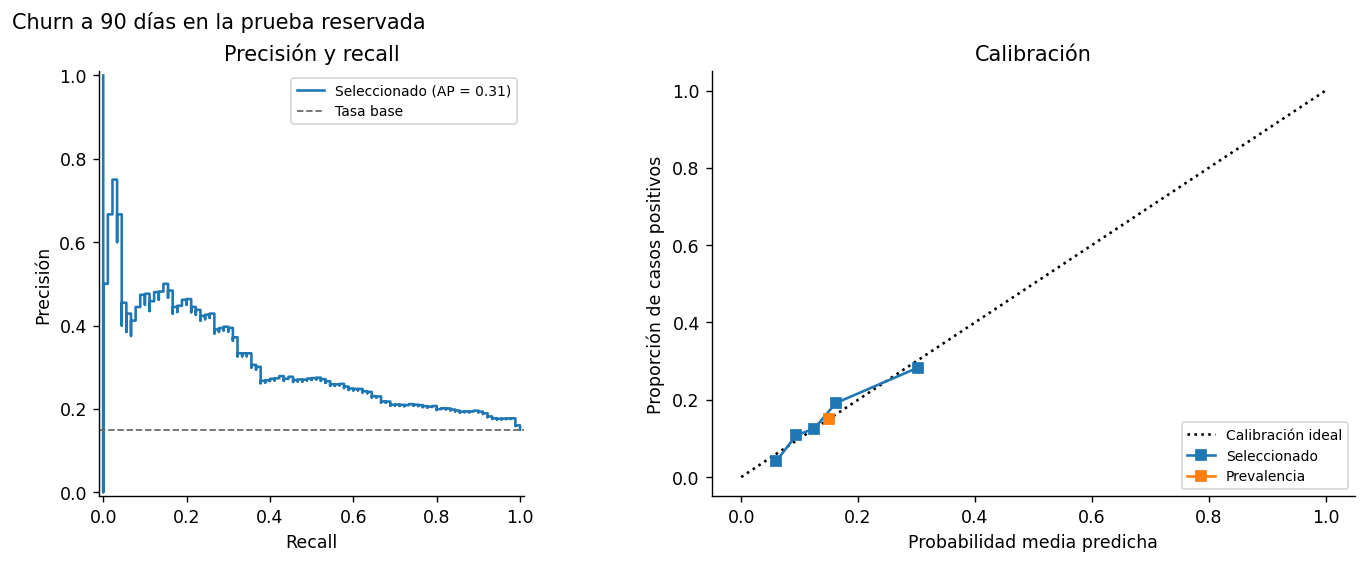

In [5]:
actual = y.iloc[test]
heldout_metrics = {key: metrics(actual, scores) for key, scores in heldout.items()}
test_table = pd.DataFrame.from_dict(heldout_metrics, orient="index")
test_table.index.names = ["Escenario", "Modelo"]
display(test_table.round(3))

capacity = pd.DataFrame([
    {"Escenario": key[0], "Modelo": key[1], "Capacidad": f"{fraction:.0%}",
     **at_capacity(actual, scores, fraction)}
    for key, scores in heldout.items()
    for fraction in (0.10, 0.20)
])
display(capacity.set_index(["Escenario", "Modelo", "Capacidad"]).round(3))

bootstrap = np.random.default_rng(seed)
indices = [np.flatnonzero(actual.to_numpy() == value) for value in (0, 1)]
resampled = [np.concatenate([bootstrap.choice(idx, len(idx), replace=True) for idx in indices])
             for _ in range(1000)]
winner_model = winner[1]
winning_scores = heldout[winner]
reference_scores = heldout["Foto", "Prevalencia"]

def bootstrap_intervals(actual, values):
    table = pd.DataFrame([metrics(actual.iloc[idx], values[idx]) for idx in resampled])
    return table[["ROC-AUC", "AP"]].quantile([0.025, 0.975]).T.set_axis(
        ["IC 95 % inferior", "IC 95 % superior"], axis=1
    )

display(bootstrap_intervals(actual, winning_scores).round(3))
snapshot_scores = heldout["Foto", winner_model]
history_scores = heldout["Foto + historial", winner_model]
auc_differences = [
    roc_auc_score(actual.iloc[idx], history_scores[idx])
    - roc_auc_score(actual.iloc[idx], snapshot_scores[idx])
    for idx in resampled
]
delta_lower, delta_upper = np.quantile(auc_differences, [0.025, 0.975])
print("IC 95 % pareado del cambio en ROC-AUC al añadir historial  "
      f"[{decimal(delta_lower)}, {decimal(delta_upper)}]")
comparison_plots(actual, {"Seleccionado": winning_scores, "Prevalencia": reference_scores},
                 "Churn a 90 días en la prueba reservada")

In [6]:
best = heldout_metrics[winner]
target = 0.75
status = "alcanzó" if best["ROC-AUC"] >= target else "quedó por debajo de"
top = at_capacity(actual, winning_scores, 0.20)
same_model_delta = (
    heldout_metrics["Foto + historial", winner_model]["ROC-AUC"]
    - heldout_metrics["Foto", winner_model]["ROC-AUC"]
)
best_observed = max(heldout_metrics, key=lambda key: heldout_metrics[key]["ROC-AUC"])
observed = heldout_metrics[best_observed]
comparison = ""
if best_observed != winner:
    comparison = (
        f" **{best_observed[1]} · {best_observed[0]}** tuvo el mayor ROC-AUC observado "
        f"en prueba (**{decimal(observed['ROC-AUC'])}**). La selección ya estaba fijada "
        f"y la comparación se puede contrastar en una nueva cohorte."
    )
display(Markdown(
    f"**{winner_model} · {winner[0]}** obtuvo **ROC-AUC {decimal(best['ROC-AUC'])}** "
    f"y **AP {decimal(best['AP'])}** en prueba. El resultado {status} la meta de **0,75**. "
    f"Al priorizar {top['Revisados']} clientes, capta **{top['Positivos capturados']}/{int(actual.sum())}** "
    f"bajas con lift **{decimal(top['Lift'])}**. Con el mismo tipo de modelo, el historial adicional "
    f"cambió el ROC-AUC en **{decimal(same_model_delta)}**." + comparison
))

**CatBoost · Foto + historial** obtuvo **ROC-AUC 0,698** y **AP 0,310** en prueba. El resultado quedó por debajo de la meta de **0,75**. Al priorizar 120 clientes, capta **34/90** bajas con lift **1,889**. Con el mismo tipo de modelo, el historial adicional cambió el ROC-AUC en **0,010**. **Regresión logística L2 · Foto + historial** tuvo el mayor ROC-AUC observado en prueba (**0,716**). La selección ya estaba fijada y la comparación se puede contrastar en una nueva cohorte.

## Recomendación

Para la demo se puede mostrar el ranking offline y contrastar cuántas bajas se detectan para
distintas capacidades. Antes de usar probabilidades en atención, repetir la evaluación en futuros
cortes con etiquetas maduras, revisar calibración y asegurar que las variables del CRM correspondan
a la misma población. Los resultados provienen de datos sintéticos de una sola fecha.

## Segunda ronda · optimización de churn

La solución ganadora de **KKBox en Kaggle** construyó variables en diferentes ventanas temporales
y usó XGBoost. Como en Claro solo existe una foto de clientes, aplicamos el principio de corte
temporal al historial de tickets y comparamos XGBoost con un modelo aditivo de boosting
(**EBM**), una mezcla de probabilidades y regresiones con un conjunto reducido de señales de servicio. También revisamos el trabajo de **TabPFN** como
alternativa para datos tabulares pequeños. Esta ronda usa modelos locales con ajuste rápido
en CPU y prioriza separar el aporte del historial del aporte del estimador. Una solución publicada
por un participante de Predict Customer Churn en Kaggle también combina probabilidades de modelos
distintos. Aquí probamos esa idea con pesos iguales y evaluamos su ganancia local.

Se mantienen la prueba de 600 clientes y los cinco folds originales. Las nuevas configuraciones
se ajustan con esos folds y se eligen por ROC-AUC de desarrollo, con AP y Brier como desempates.
La prueba ya se consultó en la ronda anterior, por lo que esta comparación es retrospectiva.
Una fecha de corte posterior ofrece la verificación independiente. Como escenario operativo, también
elegimos una configuración por recall al 20 % en desarrollo y mostramos su prueba por separado.

[Kaggle KKBox](https://www.kaggle.com/c/kkbox-churn-prediction-challenge/leaderboard) ·
[Solución ganadora de Bryan Gregory](https://arxiv.org/abs/1802.03396) ·
[Explainable Boosting Machine](https://interpret.ml/docs/ebm.html) ·
[TabPFN en Nature](https://www.nature.com/articles/s41586-024-08328-6)

[Predict Customer Churn en Kaggle](https://www.kaggle.com/competitions/playground-series-s6e3) · [Solución publicada por participante](https://github.com/ridds-io/Telco-Customer-Churn-Prediction)

In [7]:
from xgboost import XGBClassifier

def regularized_xgb(categorical, numeric):
    transform = ColumnTransformer([
        ("categorias", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ("numericas", "passthrough", numeric),
    ])
    return make_pipeline(transform, XGBClassifier(
        n_estimators=220, learning_rate=0.035, min_child_weight=12, reg_lambda=8,
        subsample=0.8, colsample_bytree=0.85, tree_method="hist", eval_metric="logloss",
        random_state=seed, n_jobs=2,
    )), {"xgbclassifier__max_depth": [2, 3]}

In [8]:
def paired_interval(y_true, candidate, reference, metric, units=None, repetitions=750):
    rng = np.random.default_rng(seed)
    truth = np.asarray(y_true)
    if units is None:
        # Mantener el número de positivos al remuestrear clientes de la foto de churn.
        pools = [np.flatnonzero(truth == label) for label in (0, 1)]
        draws = (np.concatenate([rng.choice(pool, len(pool), replace=True) for pool in pools])
                 for _ in range(repetitions))
    else:
        groups = pd.Series(np.asarray(units)).groupby(lambda i: units[i], sort=False).indices
        pools = list(groups.values())
        sampled = rng.integers(len(pools), size=(repetitions, len(pools)))
        draws = (np.concatenate([pools[i] for i in draw]) for draw in sampled)
    differences = [
        metric(truth[idx], candidate[idx]) - metric(truth[idx], reference[idx])
        for idx in draws if np.unique(truth[idx]).size == 2
    ]
    return np.quantile(differences, [0.025, 0.975])

def prediction_report(y_true, scores, reference, metric, units=None):
    rows = []
    for label, values in scores.items():
        lo, hi = paired_interval(y_true, values, reference, metric, units=units)
        capacity = at_capacity(y_true, values, 0.20)
        rows.append({
            "Modelo o escenario": label, **metrics(y_true, values),
            "Cambio de métrica principal": metric(y_true, values) - metric(y_true, reference),
            "IC 95 % inferior": lo, "IC 95 % superior": hi,
            "Capturados al 20 %": capacity["Positivos capturados"],
            "Precisión al 20 %": capacity["Precisión"], "Recall al 20 %": capacity["Recall"],
            "Lift al 20 %": capacity["Lift"],
        })
    return pd.DataFrame(rows).set_index("Modelo o escenario")

In [9]:
import warnings

from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.impute import MissingIndicator
from sklearn.preprocessing import SplineTransformer

# EBM predice con datos faltantes. Su alerta concierne a las gráficas internas de EBM;
# en este experimento solo se visualizan las probabilidades y métricas de comparación.
warnings.filterwarnings(
    "ignore", message="Missing values detected[.] Our visualizations",
    category=UserWarning, module="interpret[.]glassbox[.]_ebm[.]_ebm",
)

past = tickets.loc[tickets["fecha_creacion"].lt(cutoff)].copy()
past["dias_antes"] = (cutoff - past["fecha_creacion"]).dt.total_seconds() / 86400
assert past["dias_antes"].gt(0).all()
past["peso_contacto"] = np.exp(-np.log(2) * past["dias_antes"] / 30)
past["escalado_disponible"] = past["categoria_al_corte"].ne(unknown_category) & past["escalado"].eq(1)

def aggregate_recent(days):
    recent = past.loc[past["dias_antes"].le(days)]
    return recent.groupby("cliente_id").agg(
        abiertos=("dias_antes", "size"),
        escalados=("escalado_disponible", "sum"),
        peso=("peso_contacto", "sum"),
    )

stronger = feature_sets["Foto + historial"].copy()
for days in (7, 30, 90):
    aggregates = aggregate_recent(days)
    for field in ("abiertos", "escalados", "peso"):
        if (field, days) in {("abiertos", 90), ("escalados", 7), ("peso", 7), ("peso", 30)}:
            continue
        stronger[f"{field}_{days}d"] = clients["cliente_id"].map(aggregates[field]).fillna(0)
stronger["proporcion_tickets_recientes"] = stronger["abiertos_30d"] / (1 + stronger["tickets_90d"])
assert stronger["abiertos_7d"].le(stronger["abiertos_30d"]).all()
assert stronger["abiertos_30d"].le(computed_90d).all()
assert stronger["escalados_30d"].le(stronger["escalados_90d"]).all()
assert not {"escalado", "satisfaccion", "tiempo_resolucion_horas", "churn_90d", "cliente_id"} & set(stronger)

advanced_features = {"Foto": snapshot, "Historial ampliado": stronger}
advanced_models = {}
for scenario, X in advanced_features.items():
    numeric = [field for field in X if field not in cat]
    logistic = tabular_models(cat, numeric)["Regresión logística L2"]
    advanced_models[scenario] = {
        "Regresión logística L2": logistic,
        "XGBoost regularizado": regularized_xgb(cat, numeric),
        "EBM": (ExplainableBoostingClassifier(
            max_bins=64, max_interaction_bins=16, outer_bags=6, max_rounds=1200,
            learning_rate=0.035, min_samples_leaf=12, early_stopping_rounds=50,
            random_state=seed, n_jobs=2,
        ), {"interactions": [0, 3]}),
    }

# Contraste de complejidad: un conjunto compacto de señales ligadas al servicio.
compact_categorical = ["tipo_servicio"]
continuous = ["antiguedad_meses", "dias_mora", "nps_ultimo", "valor_mensual"]
counts = ["tickets_90d", "tickets_tecnicos_90d", "caidas_servicio_90d", "ofertas_retencion_12m"]
compact_numeric = continuous + counts
compact_name = "Señales de servicio"
advanced_features[compact_name] = snapshot[compact_categorical + compact_numeric].copy()
additive_transform = ColumnTransformer([
    ("servicio", OneHotEncoder(handle_unknown="ignore", sparse_output=False), compact_categorical),
    ("curvas", make_pipeline(SimpleImputer(strategy="median"), SplineTransformer(
        n_knots=4, degree=2, include_bias=False
    ), StandardScaler()), continuous),
    ("conteos", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), counts),
    ("faltantes", MissingIndicator(features="all"), compact_numeric),
])
advanced_models[compact_name] = {
    "Regresión logística L2": tabular_models(compact_categorical, compact_numeric)["Regresión logística L2"],
    "Regresión logística con splines": (
        make_pipeline(additive_transform, LogisticRegression(solver="liblinear", random_state=seed)),
        {"logisticregression__C": [0.03, 0.3, 3.0]},
    ),
}

with threadpool_limits(limits=2):
    advanced_picks = choose_models(advanced_features, advanced_models, y, splits, ranking)

dev_summary = advanced_picks[["Escenario", "Modelo", *ranking, "Parámetros"]].copy()
advanced_oof = {(r["Escenario"], r["Modelo"]): r["oof"] for _, r in advanced_picks.iterrows()}
members = [
    ("Historial ampliado", "Regresión logística L2"),
    ("Historial ampliado", "XGBoost regularizado"),
    ("Historial ampliado", "EBM"),
]
blend_key = ("Historial ampliado", "Promedio de tres modelos")
blend_oof = np.mean([advanced_oof[key] for key in members], axis=0)
fold_results = pd.DataFrame([metrics(y.iloc[val], blend_oof[val]) for _, val in splits])
dev_summary.loc[len(dev_summary)] = {
    "Escenario": blend_key[0], "Modelo": blend_key[1], **fold_results.mean().to_dict(),
    "Parámetros": {"ponderación": "un tercio por modelo"},
}
dev_summary = dev_summary.sort_values(ranking, ascending=[False, False, True], kind="stable")
advanced_winner = tuple(dev_summary.iloc[0][["Escenario", "Modelo"]])
baseline_cv = picks.loc[
    picks["Escenario"].eq(winner[0]) & picks["Modelo"].eq(winner[1]), ranking
].iloc[0]
display(dev_summary.set_index(["Escenario", "Modelo"]).round(3))
print(f"Selección de la ronda  {' · '.join(advanced_winner)}")
print(f"ROC-AUC de validación del modelo anterior  {decimal(baseline_cv['ROC-AUC'])}")

# La selección operativa se hace sobre predicciones de validación, con el mismo volumen por fold.
capacity_candidates = {
    **{f"{key[1]} · {key[0]}": values for key, values in advanced_oof.items()},
    f"{blend_key[1]} · {blend_key[0]}": blend_oof,
}
for baseline_key, name in [
    (winner, "CatBoost seleccionado previamente"),
    (("Foto + historial", "Regresión logística L2"), "Logística anterior · Foto + historial"),
]:
    entry = picks.loc[picks["Escenario"].eq(baseline_key[0]) & picks["Modelo"].eq(baseline_key[1])].iloc[0]
    capacity_candidates[name] = entry["oof"]
capacity_dev = pd.Series({
    name: np.mean([at_capacity(y.iloc[val], scores[val], 0.20)["Recall"] for _, val in splits])
    for name, scores in capacity_candidates.items()
}, name="Recall medio al 20 % en desarrollo").sort_values(ascending=False, kind="stable")
capacity_winner = capacity_dev.index[0]
display(capacity_dev.round(3).to_frame())


ROC-AUC     AP  Brier  \
Escenario           Modelo                                                   
Señales de servicio Regresión logística L2             0.709  0.344  0.116   
Foto                EBM                                0.706  0.342  0.117   
Señales de servicio Regresión logística con splines    0.704  0.333  0.118   
Historial ampliado  Promedio de tres modelos           0.702  0.335  0.117   
                    EBM                                0.700  0.326  0.118   
                    XGBoost regularizado               0.700  0.326  0.118   
Foto                Regresión logística L2             0.699  0.340  0.117   
                    XGBoost regularizado               0.698  0.323  0.118   
Historial ampliado  Regresión logística L2             0.690  0.323  0.119   

                                                                                  Parámetros  
Escenario           Modelo                                                                    
Señales de servicio Regresión logística L2                    {'logisticregression__C': 0.1}  
Foto                EBM                                                  {'interactions': 0}  
Señales de servicio Regresión logística con splines           {'logisticregression__C': 3.0}  
Historial ampliado  Promedio de tres modelos         {'ponderación': 'un tercio por modelo'}  
                    EBM                                                  {'interactions': 0}  
                    XGBoost regularizado                     {'xgbclassifier__max_depth': 2}  
Foto                Regresión logística L2                    {'logisticregression__C': 0.1}  
                    XGBoost regularizado                     {'xgbclassifier__max_depth': 2}  
Historial ampliado  Regresión logística L2                    {'logisticregression__C': 0.1}

Selección de la ronda  Señales de servicio · Regresión logística L2
ROC-AUC de validación del modelo anterior  0,713


,Recall medio al 20 % en desarrollo
CatBoost seleccionado previamente,0.429
Regresión logística L2 · Señales de servicio,0.415
Regresión logística con splines · Señales de servicio,0.413
EBM · Foto,0.413
Promedio de tres modelos · Historial ampliado,0.407
Regresión logística L2 · Foto,0.402
XGBoost regularizado · Foto,0.390
Logística anterior · Foto + historial,0.388
XGBoost regularizado · Historial ampliado,0.385
EBM · Historial ampliado,0.382


,ROC-AUC,AP,Brier,Cambio de métrica principal,IC 95 % inferior,IC 95 % superior,Capturados al 20 %,Precisión al 20 %,Recall al 20 %,Lift al 20 %
Modelo o escenario,,,,,,,,,,
Regresión logística L2 · Señales de servicio,0.704,0.366,0.114,0.006,-0.021,0.032,38,0.317,0.422,2.111
EBM · Foto,0.696,0.314,0.117,-0.002,-0.021,0.017,37,0.308,0.411,2.056
Regresión logística con splines · Señales de servicio,0.695,0.355,0.115,-0.003,-0.029,0.023,37,0.308,0.411,2.056
Promedio de tres modelos · Historial ampliado,0.709,0.375,0.114,0.010,-0.009,0.031,36,0.300,0.400,2.000
EBM · Historial ampliado,0.703,0.350,0.116,0.005,-0.014,0.024,33,0.275,0.367,1.833
XGBoost regularizado · Historial ampliado,0.686,0.341,0.117,-0.013,-0.036,0.012,35,0.292,0.389,1.944
Regresión logística L2 · Foto,0.714,0.380,0.113,0.016,-0.011,0.041,40,0.333,0.444,2.222
XGBoost regularizado · Foto,0.688,0.343,0.116,-0.010,-0.034,0.016,36,0.300,0.400,2.000
Regresión logística L2 · Historial ampliado,0.712,0.389,0.113,0.014,-0.012,0.040,36,0.300,0.400,2.000


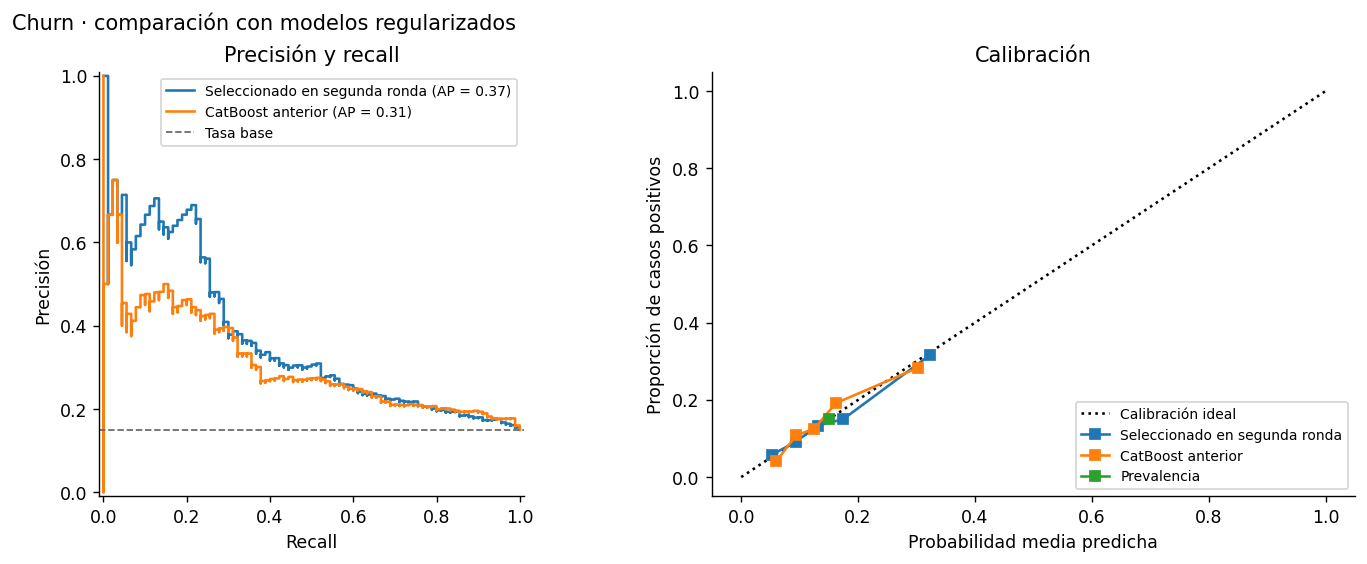

**Regresión logística L2 · Señales de servicio** fue seleccionado en desarrollo. En prueba obtuvo **ROC-AUC 0,704** y capturó **38/90** bajas con capacidad del 20 %. Frente al CatBoost anterior, el cambio de ROC-AUC tiene IC 95 % pareado **[-0,021; 0,032]**. El mayor ROC-AUC observado entre las alternativas de esta ronda fue **0,714** con **Regresión logística L2 · Foto**.

Con el criterio operativo de recall al 20 %, se seleccionó en desarrollo **CatBoost seleccionado previamente**. Capturó **34/90** bajas en prueba, con lift **1,889**.

In [10]:
with threadpool_limits(limits=2):
    advanced_test = test_models(advanced_picks, advanced_features, advanced_models, y, dev, test)
advanced_test[blend_key] = np.mean([advanced_test[key] for key in members], axis=0)

advanced_scores = {
    f"{row['Modelo']} · {row['Escenario']}": advanced_test[row["Escenario"], row["Modelo"]]
    for _, row in dev_summary.iterrows()
}
advanced_scores["CatBoost seleccionado previamente"] = winning_scores
advanced_scores["Logística anterior · Foto + historial"] = heldout["Foto + historial", "Regresión logística L2"]
report = prediction_report(actual, advanced_scores, winning_scores, roc_auc_score)
display(report.round(3))
final_candidate = advanced_test[advanced_winner]
observed_key = max(advanced_test, key=lambda key: roc_auc_score(actual, advanced_test[key]))
advanced_selection = metrics(actual, final_candidate)
observed_score = roc_auc_score(actual, advanced_test[observed_key])
new_capture = at_capacity(actual, final_candidate, 0.20)
interval = report.loc[f"{advanced_winner[1]} · {advanced_winner[0]}", ["IC 95 % inferior", "IC 95 % superior"]]
comparison_plots(actual, {
    "Seleccionado en segunda ronda": final_candidate,
    "CatBoost anterior": winning_scores, "Prevalencia": reference_scores,
}, "Churn · comparación con modelos regularizados")
display(Markdown(
    f"**{advanced_winner[1]} · {advanced_winner[0]}** fue seleccionado en desarrollo. "
    f"En prueba obtuvo **ROC-AUC {decimal(advanced_selection['ROC-AUC'])}** "
    f"y capturó **{new_capture['Positivos capturados']}/{int(actual.sum())}** bajas con capacidad del 20 %. "
    f"Frente al CatBoost anterior, el cambio de ROC-AUC tiene IC 95 % pareado "
    f"**[{decimal(interval.iloc[0])}; {decimal(interval.iloc[1])}]**. "
    f"El mayor ROC-AUC observado entre las alternativas de esta ronda fue "
    f"**{decimal(observed_score)}** con **{observed_key[1]} · {observed_key[0]}**."
))

capacity_result = at_capacity(actual, advanced_scores[capacity_winner], 0.20)
display(Markdown(
    f"Con el criterio operativo de recall al 20 %, se seleccionó en desarrollo "
    f"**{capacity_winner}**. Capturó **{capacity_result['Positivos capturados']}/{int(actual.sum())}** "
    f"bajas en prueba, con lift **{decimal(capacity_result['Lift'])}**."
))


Los intervalos remuestrean los mismos clientes para candidato y referencia. Así muestran si un
incremento pequeño es compatible con variación de la muestra. Para confirmar una mejora temporal,
harían falta nuevas fotos con desenlaces maduros y señales fechadas de facturación, caídas o
campañas, como las series de transacciones y actividad que tenía KKBox.